# Shape Transformation using Variational Implicit Functions Notebook Implementation

Notebook implementation by Andy Thai

Sample implementation: https://github.com/fiji/VIB/blob/master/src/main/java/Implicit_Interpolate_Binary.java

In [1]:
%load_ext autoreload
%autoreload 2

## Import libraries

In [20]:
# Standard library test
import time
from pprint import pprint
import glob

# Third-party libraries
import numpy as np
import matplotlib.pyplot as plt
import scipy
#from jupyterthemes import jtplot; jtplot.style()

# My libraries
from modules.implicit import ImplicitFunction
import modules.utils as utils

## Setup sample 3D example

In [21]:
lv = "data/npy/lv.npy"
volume = np.load(lv)
where_1 = np.where(volume != 0)
volume[where_1] = 1

## 4D Test

(2, 10, 216, 256)
DEBUG: Creating constraints.
Grid constraints created.
(1784, 4)
DEBUG: Finished creating constraints.
Elapsed time: 0.2270512580871582

DEBUG: Creating matrix.


Creating matrix:   0%|          | 0/1784 [00:00<?, ?it/s]

DEBUG: Finished constructing matrix
Elapsed time: 0.5967106819152832

DEBUG: Solving matrix.
DEBUG: Finished solving matrix.
Elapsed time: 0.03202342987060547
Output dimensions: (10, 216, 256)
Threshold: 0.0


Interpolating volume stack:   0%|          | 0/2160 [00:00<?, ?it/s]

Done!
(10, 216, 256)


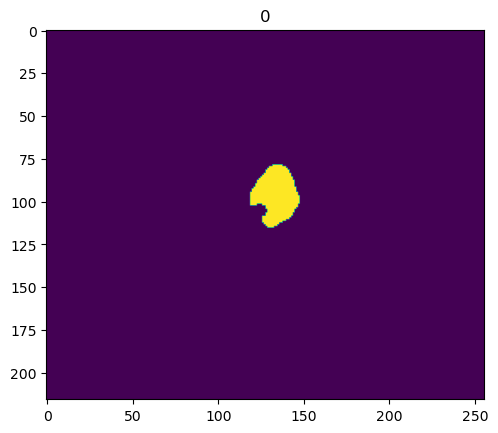

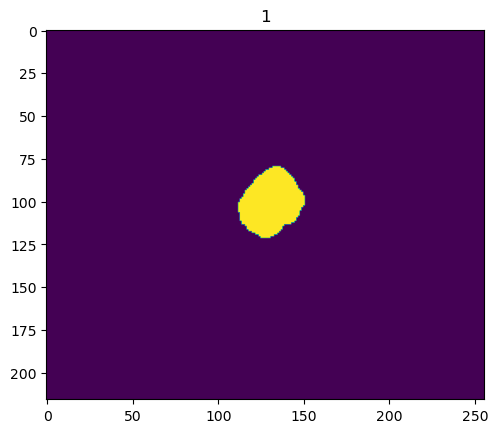

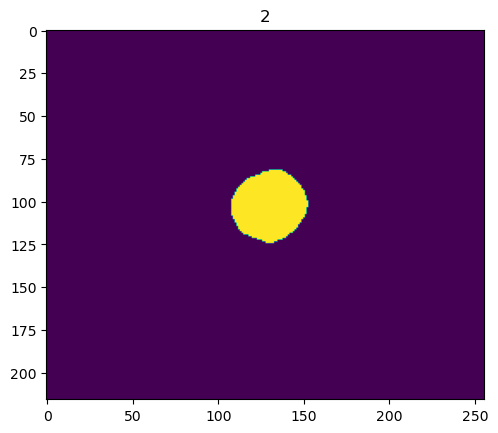

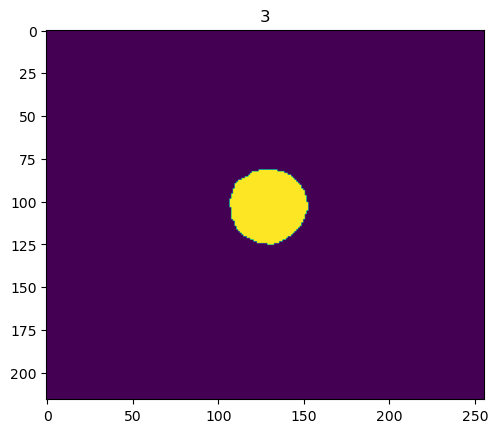

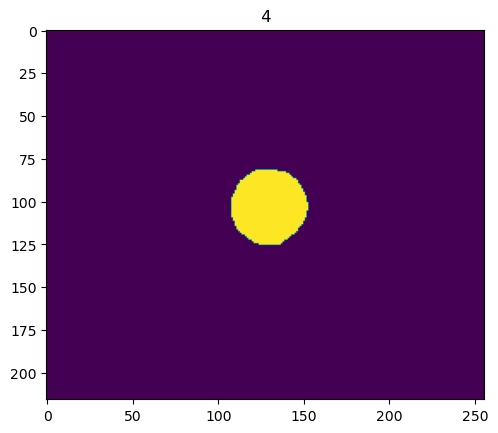

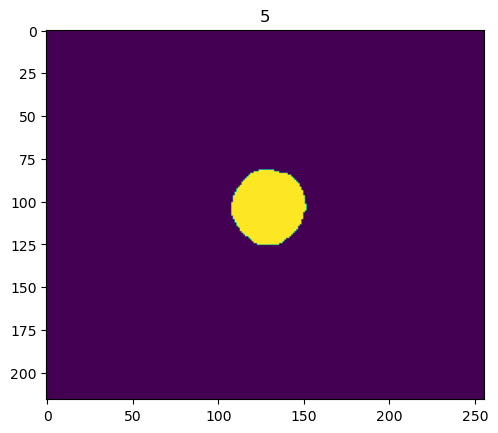

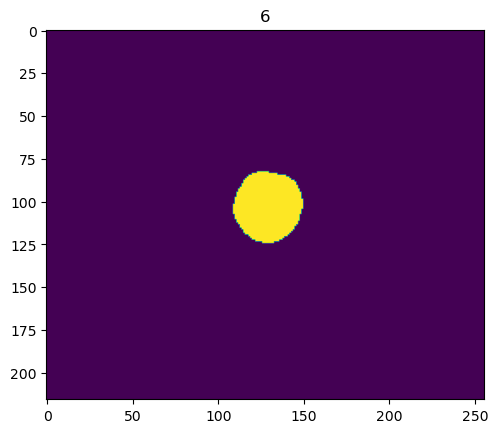

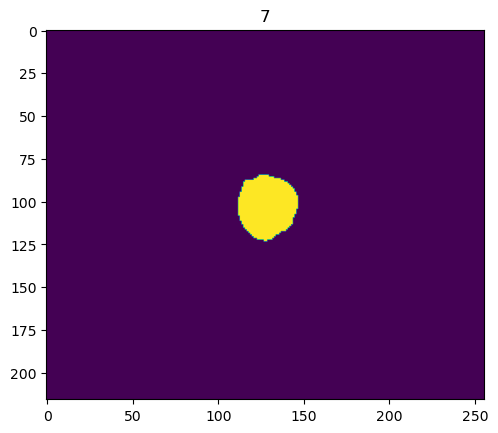

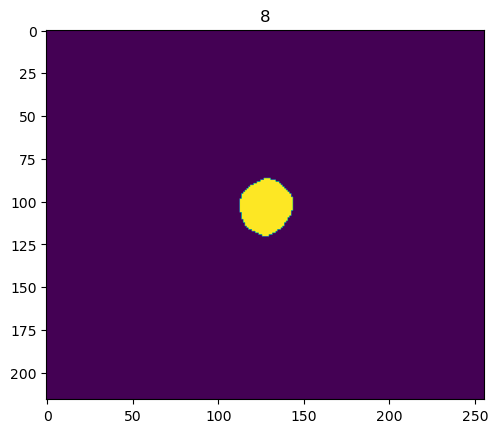

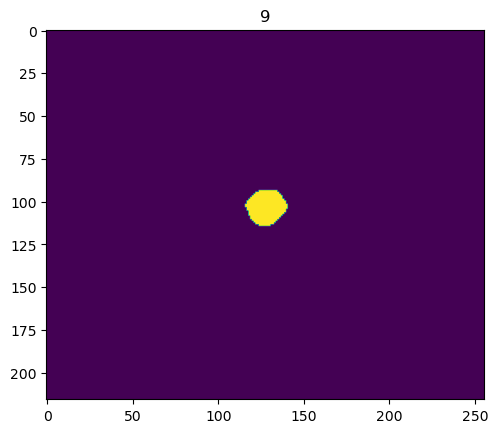

In [44]:
# Try 3D to 3D
Ma = volume[0, :]
Mb = volume[15, :]
Mab = np.array([Ma, Mb])
np.save('output/M0.npy', Ma)
np.save('output/M15.npy', Mb)
print(Mab.shape)

imp = ImplicitFunction(Mab, tmax=1)
img = imp.interpolate(0.5)

np.save('output/M0-M15-interp.npy', img)

print(img.shape)
for i in range(img.shape[0]):
    plt.imshow(img[i])
    plt.title(str(i))
    plt.show()

In [32]:
from pprint import pprint
pprint(imp.data.constraints4D[0][0])

[(array([0., 0., 0., 0.]), -141.12136840820312),
 (array([ 0., 21.,  0.,  0.]), -128.98046875),
 (array([ 0., 42.,  0.,  0.]), -119.14398193359375),
 (array([ 0., 63.,  0.,  0.]), -111.76551818847656),
 (array([ 0., 84.,  0.,  0.]), -107.40958404541016),
 (array([  0., 105.,   0.,   0.]), -106.0428466796875),
 (array([  0., 126.,   0.,   0.]), -107.25440979003906),
 (array([  0., 147.,   0.,   0.]), -112.36875915527344),
 (array([  0., 168.,   0.,   0.]), -120.92080688476562),
 (array([  0., 189.,   0.,   0.]), -132.0496063232422),
 (array([  0., 210.,   0.,   0.]), -144.71151733398438),
 (array([25.,  0.,  0.,  0.]), -122.65936279296875),
 (array([25., 21.,  0.,  0.]), -108.48953247070312),
 (array([25., 42.,  0.,  0.]), -96.81753540039062),
 (array([25., 63.,  0.,  0.]), -88.02873229980469),
 (array([25., 84.,  0.,  0.]), -82.79853057861328),
 (array([ 25., 105.,   0.,   0.]), -81.05622863769531),
 (array([ 25., 126.,   0.,   0.]), -82.63945007324219),
 (array([ 25., 147.,   0.,   0.

In [17]:
def polyArea2D(pts):
    # https://stackoverflow.com/questions/19873596/convex-hull-area-in-python
    lines = np.hstack([pts,np.roll(pts,-1,axis=0)])
    area = 0.5*abs(sum(x1*y2-x2*y1 for x1,y1,x2,y2 in lines))
    return area

def ejection_fraction_data(mat: np.ndarray):
    min_volume = np.inf
    max_volume = -np.inf
    for t in range(mat.shape[0]):
        curr = mat[t]
        curr_volume = np.count_nonzero(curr)
        if curr_volume > max_volume:
            max_volume = curr_volume
        if curr_volume < min_volume:
            min_volume = curr_volume
    return min_volume / max_volume

def ejection_fraction_convex(imp: ImplicitFunction):
    constraints4D = imp.data.constraints4D
    min_volume = np.inf
    max_volume = -np.inf
    for t in sorted(constraints4D.keys()):
        curr_volume = 0
        constraints3D = constraints4D[t]
        for z in sorted(constraints3D.keys()):
            boundary_constraints = []
            for pt, pt_dist in constraints3D[z]:
                if pt_dist == 0:
                    boundary_constraints.append(pt[:2])
            # Compute area of boundary constraints
            #print(boundary_constraints)
            curr_volume += polyArea2D(boundary_constraints)
        # Compute volume of current timestep
        if curr_volume > max_volume:
            max_volume = curr_volume
        if curr_volume < min_volume:
            min_volume = curr_volume
    return min_volume / max_volume

In [40]:
#imp = ImplicitFunction(Mab, tmax=1)
#img1 = imp.interpolate(0)
#img2 = imp.interpolate(1)

print('Implicit ejection fraction (convex):', ejection_fraction_convex(imp))
#print('Implicit ejection fraction (estimate):', ejection_fraction_data(np.array([img1, img2])))
print('Original ejection fraction:', ejection_fraction_data(Mab))

Implicit ejection fraction (convex): 0.8104541337818605
Original ejection fraction: 0.8107745237895444


Multiple 4D interp

(5, 10, 216, 256)
DEBUG: Creating constraints.
Grid constraints created.
(4454, 4)
DEBUG: Finished creating constraints.
Elapsed time: 0.5884866714477539

DEBUG: Creating matrix.


Creating matrix:   0%|          | 0/4454 [00:00<?, ?it/s]

DEBUG: Finished constructing matrix
Elapsed time: 3.784388542175293

DEBUG: Solving matrix.
DEBUG: Finished solving matrix.
Elapsed time: 0.5096144676208496
Output dimensions: (10, 216, 256)
Threshold: 0.0


Interpolating volume stack:   0%|          | 0/2160 [00:00<?, ?it/s]

Done!
(10, 216, 256)


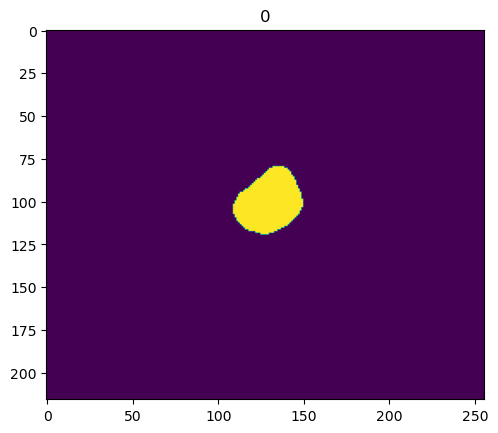

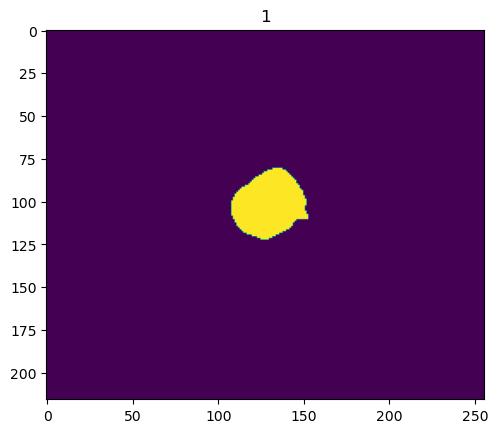

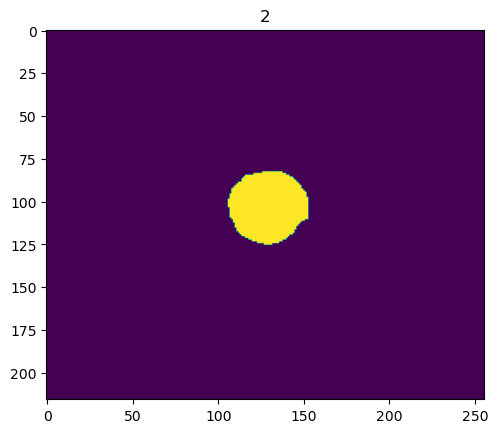

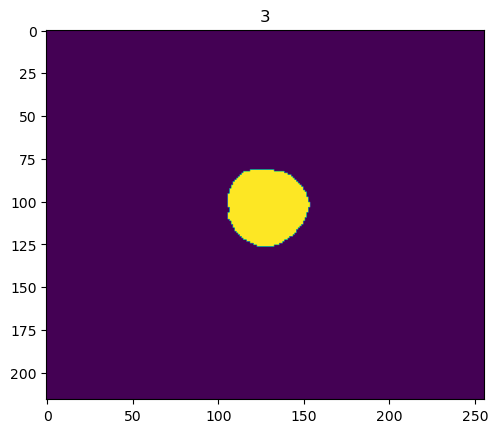

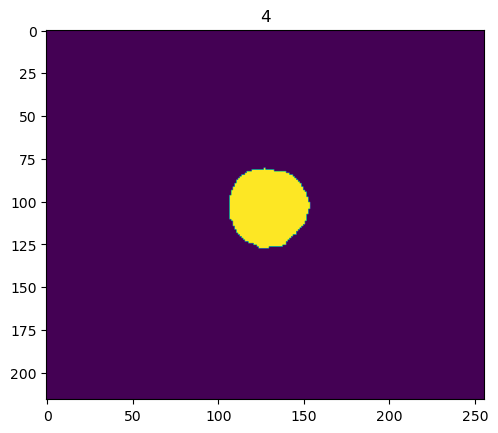

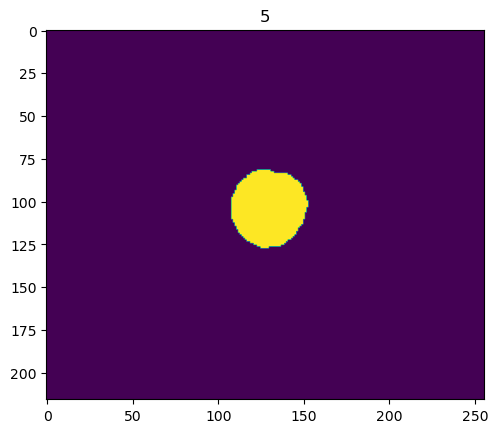

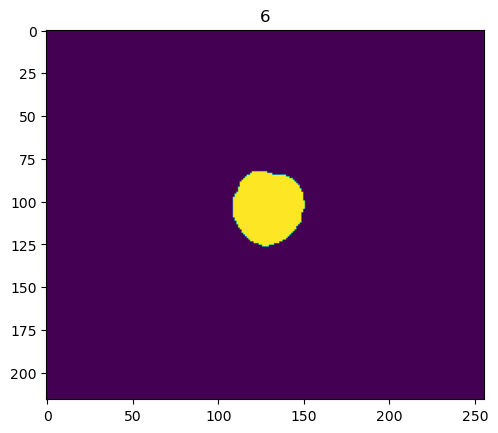

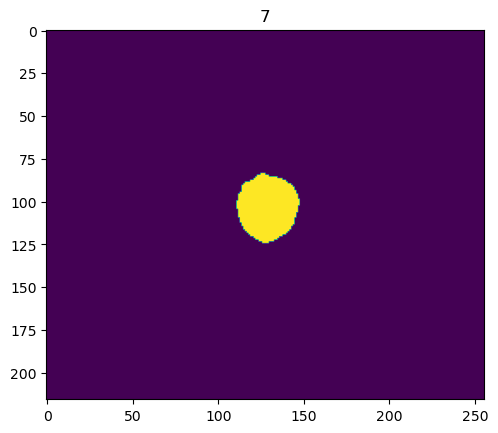

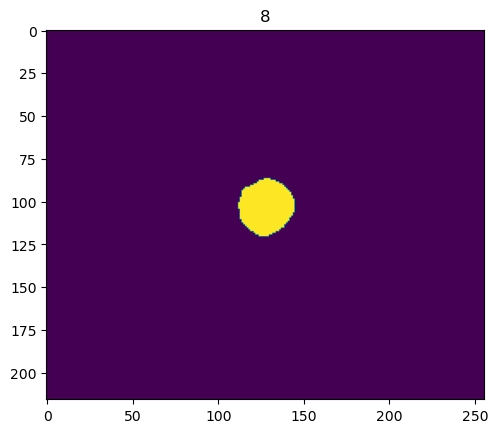

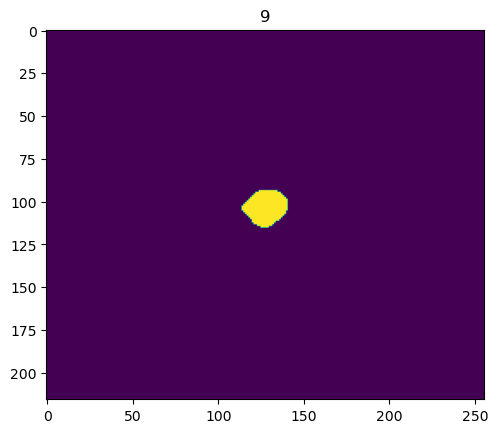

In [43]:
# Try 4D multiple
M = volume[:, :, :, :]
np.save('output/M0-M4.npy', M)
print(M.shape)

imp = ImplicitFunction(M, tmax=M.shape[0] - 1)

#for i in range()
img = imp.interpolate(0)

np.save('output/M0-M4-0-interp.npy', img)

print(img.shape)
for i in range(img.shape[0]):
    plt.imshow(img[i])
    plt.title(str(i))
    plt.show()